# Demanda agregada e contribuições à variação real do PIB (Brasil, 1996–2025)

Este notebook decompõe o PIB brasileiro pela ótica da despesa (consumo, investimento, gasto público e exportações líquidas) e mostra quanto cada componente contribuiu para a variação real do PIB ao longo do tempo. É a primeira etapa de um projeto de macroeconomia aplicada, que segue com a curva de Phillips e um simulador de choques de demanda e oferta.

## Dados

- **Fonte:** IBGE, Contas Nacionais Trimestrais, coletadas pela API do SIDRA.
- **Tabela 1846:** valores a preços correntes (R$ milhões). Usada nas participações dos componentes no PIB.
- **Tabela 6612:** valores encadeados a preços de 1995 (R$ milhões). Usada nas contribuições à variação do PIB.
- **Período:** 1996 a 2025. 2026 fica de fora por estar incompleto.
- **Data da coleta:** 18/10/2026. O IBGE revisa a série histórica, então os valores podem mudar em coletas futuras.

As duas tabelas não se misturam: valores correntes e valores reais só são comparados dentro da própria base.

## Metodologia

A identidade do PIB pela ótica da despesa é:

$$Y = C + I + G + (X - M)$$

- **C:** despesa de consumo das famílias.
- **I:** investimento, definido como formação bruta de capital fixo (FBCF) mais variação de estoque.
- **G:** despesa de consumo da administração pública. Investimentos públicos ficam dentro da FBCF.
- **X − M:** exportações menos importações de bens e serviços.

A contribuição de cada componente à variação real do PIB, em pontos percentuais, é a variação do componente dividida pelo PIB do ano anterior:

$$\text{contribuição}_t = \frac{\text{componente}_t - \text{componente}_{t-1}}{PIB_{t-1}} \times 100$$

A importação entra com sinal negativo. A tabela real (6612) não traz variação de estoque, então o investimento é representado apenas pela FBCF. A barra **"Estoques e resíduo"** é a diferença entre a variação do PIB e a soma das contribuições, e reúne a variação de estoques e a não aditividade das séries encadeadas.

In [ ]:
import pandas as pd, matplotlib.pyplot as plt

In [25]:
despesas_anuais = pd.read_csv('../dados/despesas_anuais_nominal.csv', sep=';', index_col='Ano')

# Consumo
C = despesas_anuais['Despesa de consumo das famílias']
# Investimento
I = despesas_anuais['Formação bruta de capital fixo'] + despesas_anuais['Variação de estoque']
# Gasto Público
G = despesas_anuais['Despesa de consumo da administração pública']
# Exportações
X = despesas_anuais['Exportação de bens e serviços']
# Importações
M = despesas_anuais['Importação de bens e serviços (-)']

demanda_agregada_anual = C + I + G + (X - M)


## Validação

Como a identidade vale por definição, a soma C + I + G + (X − M) em valores correntes deve coincidir com o PIB publicado pelo IBGE. A diferença máxima encontrada foi de **R$ 4 milhões** no ano, o que corresponde a arredondamento, já que os componentes são publicados em milhões inteiros.

In [47]:
dif = (demanda_agregada_anual - despesas_anuais['PIB a preços de mercado']).abs().max()
print(f'Diferença máxima entre C+I+G+X−M e o PIB: R$ {dif:,.0f} milhões')

Diferença máxima entre C+I+G+X−M e o PIB: R$ 4 milhões


## Gráfico 1: demanda agregada a preços correntes

A linha mostra a soma C + I + G + (X − M) em trilhões de reais correntes. Por construção, ela é o próprio PIB nominal. A trajetória crescente mistura expansão real e inflação, então ela não indica, sozinha, quanto a economia cresceu em volume. Para isso servem as contribuições do gráfico 3.

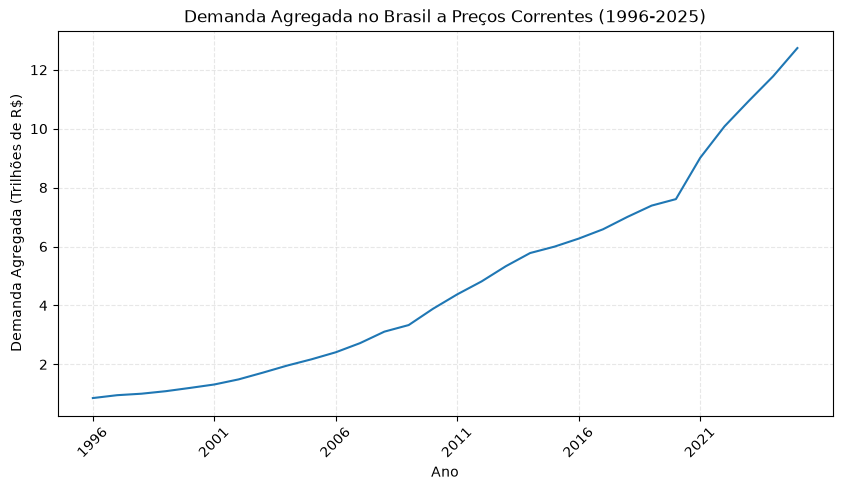

In [48]:
# Converte os valores para trilhões de reais
da_anual_trilhoes = demanda_agregada_anual / 1000000

plt.figure(figsize=(10, 5))
plt.plot(da_anual_trilhoes.index, da_anual_trilhoes.values)
plt.title('Demanda Agregada no Brasil a Preços Correntes (1996-2025)')
plt.xlabel('Ano')
plt.ylabel('Demanda Agregada (Trilhões de R$)')
plt.xticks(da_anual_trilhoes.index[::5], rotation=45)
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

## Gráfico 2: composição da demanda agregada

Participação de cada componente no total, em valores correntes. Como numerador e denominador estão a preços do mesmo ano, a composição pode ser lida sem deflacionar. O consumo das famílias é o maior componente em todos os anos, entre cerca de 60% e 65% da demanda agregada. O gasto público é o mais estável, na faixa de 18% a 20%. Entre os componentes domésticos, o investimento é o que mais oscila: chega a cerca de 22% no começo da década de 2010, cai para perto de 15% em 2016–2017 e não volta àquele patamar até o fim da série. Exportações e importações mudam de patamar: as exportações saem de cerca de 7% no fim dos anos 1990 para algo entre 18% e 19% depois de 2020, e as importações de cerca de 9% para algo entre 16% e 19%, o que sugere maior abertura comercial, embora parte do movimento possa refletir câmbio e preços relativos. As importações aparecem positivas no gráfico, mas entram subtraindo no total (C + I + G + X − M = 100%).

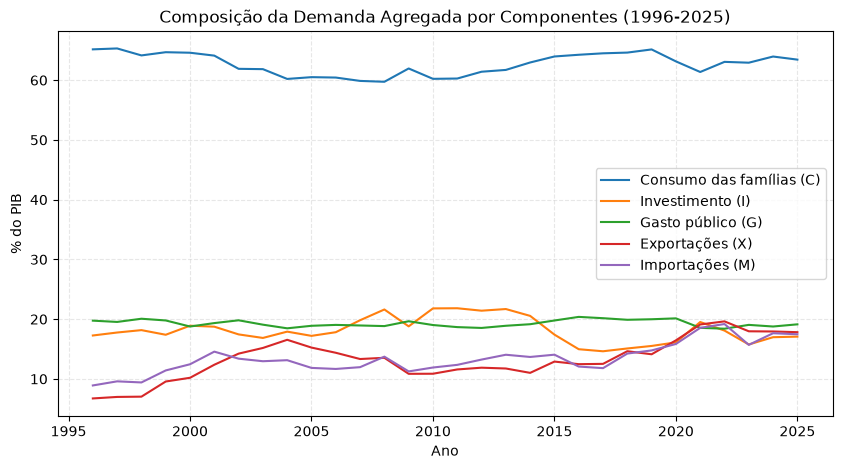

In [52]:
# Cálculo da composição da DA (em pontos percentuais)
dan = demanda_agregada_anual
part = pd.DataFrame({
    "Consumo das famílias (C)": C / dan,
    "Investimento (I)": I / dan,
    "Gasto público (G)": G / dan,
    "Exportações (X)": X / dan,
    "Importações (M)": M / dan,
}) * 100

part.plot(figsize=(10, 5))
plt.title("Composição da Demanda Agregada por Componentes (1996-2025)")
plt.ylabel("% do PIB")
plt.grid(True, linestyle="--", alpha=0.3)
plt.show()

## Gráfico 3: contribuições à variação real do PIB

Cada barra mostra, em pontos percentuais, quanto um componente respondeu pela variação real do PIB no ano. A linha preta é a variação do PIB. Em 2016, o consumo das famílias e a FBCF foram os maiores responsáveis pela queda. Em 2020, o consumo das famílias puxou o PIB para baixo, e a queda das importações amorteceu parte do efeito. Em 2021, a FBCF e o consumo lideraram a recuperação, e o aumento das importações subtraiu parte dela. Contribuição é uma decomposição aritmética: ela mostra quanto cada componente respondeu pela variação, mas não explica por que ele variou.

In [23]:
despesas_anuais_real = pd.read_csv('../dados/despesas_anuais_real.csv', sep=';', index_col='Ano')

In [ ]:
# Mapa das siglas
vol = pd.DataFrame({
    'PIB':despesas_anuais_real['PIB a preços de mercado'],
    'C': despesas_anuais_real['Despesa de consumo das famílias'],
    'G': despesas_anuais_real['Despesa de consumo da administração pública'],
    'FBCF': despesas_anuais_real['Formação bruta de capital fixo'],
    'X': despesas_anuais_real['Exportação de bens e serviços'],
    'M': despesas_anuais_real['Importação de bens e serviços (-)'],
}, index=despesas_anuais_real.index)

# Cálculo das contribuições ao crescimento (em pontos percentuais do PIB)
base = vol['PIB'].shift(1)

contrib = pd.DataFrame({
    'C': vol['C'].diff() / base,
    'G': vol['G'].diff() / base,
    'FBCF': vol['FBCF'].diff() / base,
    'X': vol['X'].diff() / base,
    'M': -vol['M'].diff() / base,  # Importação entra subtraindo
}) * 100

# Variação de estoques + não aditividade do encadeamento
contrib['Estoques e resíduo'] = vol['PIB'].pct_change() * 100 - contrib.sum(axis=1)

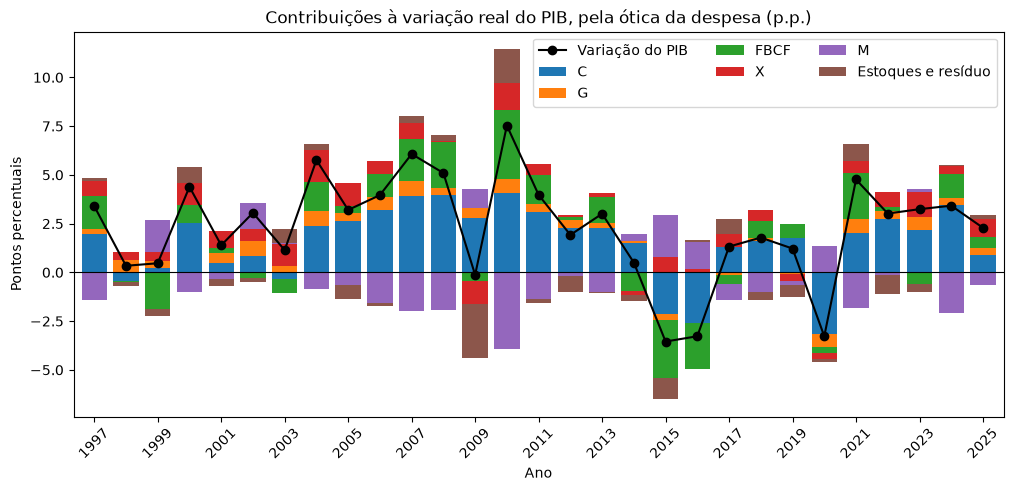

In [51]:
contrib['PIB'] = vol['PIB'].pct_change() * 100
c = contrib.dropna()

ax = c.drop(columns='PIB').plot(kind='bar', stacked=True, figsize=(12, 5), width=0.8)
ax.plot(range(len(c)), c['PIB'].values, color='black', marker='o', label='Variação do PIB')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Contribuições à variação real do PIB, pela ótica da despesa (p.p.)')
ax.set_ylabel('Pontos percentuais')
ax.set_xticks(range(0, len(c), 2), labels=c.index[::2], rotation=45)
ax.legend(ncol=3)
plt.show()

## Observações e limitações

- Na série real não há variação de estoque. O investimento real é só a FBCF, e o resíduo mistura estoques com a não aditividade do encadeamento.
- A tabela não separa investimento público de privado, e o G inclui só o consumo do governo.
- Os resultados são descritivos e não permitem concluir causalidade.
